Import Packages and Useful Function

In [1]:
import pandas as pd
from labtools.adtools import sort
import seaborn as sns
import matplotlib.pyplot as plt
# Function for writing dictionary to csv file (used for loss tables)
import csv
def write_dict_to_csv(file_path, dictionary):
    with open(file_path, 'w', newline='') as csvfile:
        writer = csv.writer(csvfile)
        writer.writerow(dictionary.keys())
        writer.writerow(dictionary.values())
dir = '/global/scratch/projects/fc_mvslab/OpenProjects/Marissa/SynADs/2024-04-00_w.labtoolsDev/2025-10-14_Reprocess/'
name = 'SynAD_RatioRep'

Initialize the sort

In [2]:
my_sort = sort.Sort(["/global/scratch/projects/fc_mvslab/data/sequencing/CZB_Apr2024/20240425/MZ_SynADs/results/ratrep1_S17.fastq.gz.assembled.fastq",
                    "/global/scratch/projects/fc_mvslab/data/sequencing/CZB_Apr2024/20240425/MZ_SynADs/results/ratrep2_S18.fastq.gz.assembled.fastq",
                    "/global/scratch/projects/fc_mvslab/data/sequencing/CZB_Apr2024/20240425/MZ_SynADs/results/ratrep3_S19.fastq.gz.assembled.fastq",
                    "/global/scratch/projects/fc_mvslab/data/sequencing/CZB_Apr2024/20240425/MZ_SynADs/results/ratrep4_S20.fastq.gz.assembled.fastq"], 
                    bin_counts = [1000000,1000000,1000000,1000000], 
                    bin_values = [12176,40720,91331,241223], 
                    design_file = "/global/scratch/projects/fc_mvslab/OpenProjects/Marissa/DesignFiles/PlantSynADs_Design.csv")

Process

In [3]:
activities, total_reads, reads_per_bin, loss_table = my_sort.process(thresh=39, ad_preceder = "GCTAGC", bc_preceder = "GGGCCCG", 
            bc_anteceder = "GGCGCGCC", ad_length = 120, bclength = 14, barcoded = True)

Opening file ratrep1_S17.fastq.gz.assembled.fastq ...
Total parsed reads = 13,585,573                      
Opening file ratrep2_S18.fastq.gz.assembled.fastq ...
Total parsed reads = 18,884,759                      
Opening file ratrep3_S19.fastq.gz.assembled.fastq ...
Total parsed reads = 17,725,109                      
Opening file ratrep4_S20.fastq.gz.assembled.fastq ...
Total parsed reads = 16,710,810                      


Outputs

In [4]:
loss_table

{'ad_preceder': 273586,
 'design_file': 3989522.0,
 'thresh': 487617.0,
 'bc_is_na': 5379.0,
 'bc_flanks': 215150,
 'bc_length': 55375}

In [5]:
# Convert Series of tuples to DataFrame with two columns
total_reads_df = total_reads.apply(pd.Series)
# Reset index to convert the tuple index into columns
total_reads_df = total_reads.reset_index()
# Rename the columns
total_reads_df.columns = ['AD', 'BC', 'Reads']
# Count the occurrences of each 'BC' and create a new Series
bc_counts = total_reads_df['BC'].value_counts()
# Assign the counts back to the original DataFrame
total_reads_df['ADs_per_BC'] = total_reads_df['BC'].map(bc_counts)
# Similarly, count the occurrences of each 'AD' and create a new Series
ad_counts = total_reads_df['AD'].value_counts()
# Assign the counts back to the original DataFrame
total_reads_df['BCs_per_AD'] = total_reads_df['AD'].map(ad_counts)
# Sum all the reads that have the same sequence in the 'AD' column
total_reads_df['numreads_per_AD'] = total_reads_df.groupby('AD')['Reads'].transform('sum')

activities.reset_index(inplace=True)
# Rename the columns for clarity
activities.rename(columns={'level_0': 'DNAseq', 'level_1': 'BC'}, inplace=True)
activities

,DNAseq,BC,0,1,2,3,Activity
0,GTTGCTCCAGCTCAACCAACTTCTGTTGAAAATTCTCCAGAATTGA...,TCAAAGGACACTAT,0.943662,0.056338,0.000000,0.000000,13784.120187
1,TATTTGTGTGATTATTTGCAAATGGGTCCAGATTTTGGTAGAGAAG...,TAAGTGACTTTATT,0.801492,0.198508,0.000000,0.000000,17842.199849
2,GTTATTGCTAAAGAAAAAAGAGAAAAAGAAGCTATGAAATTGTTGG...,TTGAGACTAGACTA,0.900512,0.099103,0.000385,0.000000,15035.269217
3,TCTTTGGCTGAATTGGAAAATGAAGGTTTGTTTGATAATGAACATG...,ACACATATGAGCAC,0.244556,0.481129,0.179793,0.094521,61790.671505
4,GATAATTTGATTTGTGATGAATCTGTTTCTGAAGATTTGGAAGGTC...,AGTCGTCATACTAC,0.954369,0.042587,0.002865,0.000179,13659.345470
...,...,...,...,...,...,...,...
45780,ACTGGTTTTACTCCATGGGAATTGAATTGTTCTGATTTGTTTTCTA...,GCATCATAATAGAA,0.000000,0.000000,0.000000,1.000000,241223.000000
45781,GAAGAAACTGCTATTTCTAATTGGTGGGAATTTACTGATTCTTGTA...,TATGGCACGAAGAT,0.000000,0.000000,0.000000,1.000000,241223.000000
45782,GATGATTTTAAAGGTTTTTTTAATGATGATGATGAATTTGATACTT...,TGAAATTAGGAAAT,0.000000,0.000000,0.000000,1.000000,241223.000000
45783,GGTGGTTTGTGTTGTTATAGAGAAGTTGGTGATGGTGATCCACAAC...,TCACGGTGAAGACA,0.000000,0.000000,0.000000,1.000000,241223.000000


QC Analyses

In [6]:
print(total_reads_df.shape, activities.shape)

(45785, 6) (45785, 7)


In [7]:
activities.head(10)

,DNAseq,BC,0,1,2,3,Activity
0,GTTGCTCCAGCTCAACCAACTTCTGTTGAAAATTCTCCAGAATTGA...,TCAAAGGACACTAT,0.943662,0.056338,0.000000,0.000000,13784.120187
1,TATTTGTGTGATTATTTGCAAATGGGTCCAGATTTTGGTAGAGAAG...,TAAGTGACTTTATT,0.801492,0.198508,0.000000,0.000000,17842.199849
2,GTTATTGCTAAAGAAAAAAGAGAAAAAGAAGCTATGAAATTGTTGG...,TTGAGACTAGACTA,0.900512,0.099103,0.000385,0.000000,15035.269217
3,TCTTTGGCTGAATTGGAAAATGAAGGTTTGTTTGATAATGAACATG...,ACACATATGAGCAC,0.244556,0.481129,0.179793,0.094521,61790.671505
4,GATAATTTGATTTGTGATGAATCTGTTTCTGAAGATTTGGAAGGTC...,AGTCGTCATACTAC,0.954369,0.042587,0.002865,0.000179,13659.345470
5,TCTCCAATTGATGATTCTGAATTGGTTAATCCAACTCCATTGCCAT...,TGAGGACCTCAACA,0.205841,0.459021,0.258237,0.076900,63332.853604
6,GGTCATTTTGAAAAAATTTCTAATGGTGTTAAAACTGAAAATGATC...,ACATATTAAAGAAA,0.992026,0.007233,0.000434,0.000307,12487.120439
7,ATGTTTGGTTTGTTGTTTGATCCATTTTCTAATGTTGTTATTTTTG...,AGGCGAAGCCGATA,0.937561,0.055775,0.000000,0.006664,15294.349324
8,TCTTCTGTTGGTGAAATTGTTGAATTGCCACCATTGGAATATATTG...,TGTCATGGGATTAT,0.969545,0.027706,0.002750,0.000000,13184.478863
9,TCTCATGTTTCTCCATATGAAGAAGATGAAATTCCACCATTGACTT...,GATGAGTGTAAAGA,1.000000,0.000000,0.000000,0.000000,12176.000000


In [8]:
total_reads_df.head(10)

,AD,BC,Reads,ADs_per_BC,BCs_per_AD,numreads_per_AD
0,GTTGCTCCAGCTCAACCAACTTCTGTTGAAAATTCTCCAGAATTGA...,TCAAAGGACACTAT,1355.0,1.0,3,2629.0
1,TATTTGTGTGATTATTTGCAAATGGGTCCAGATTTTGGTAGAGAAG...,TAAGTGACTTTATT,1536.0,1.0,2,1628.0
2,GTTATTGCTAAAGAAAAAAGAGAAAAAGAAGCTATGAAATTGTTGG...,TTGAGACTAGACTA,5952.0,1.0,5,11815.0
3,TCTTTGGCTGAATTGGAAAATGAAGGTTTGTTTGATAATGAACATG...,ACACATATGAGCAC,1945.0,1.0,2,4570.0
4,GATAATTTGATTTGTGATGAATCTGTTTCTGAAGATTTGGAAGGTC...,AGTCGTCATACTAC,8852.0,1.0,5,13545.0
5,TCTCCAATTGATGATTCTGAATTGGTTAATCCAACTCCATTGCCAT...,TGAGGACCTCAACA,5886.0,1.0,5,6998.0
6,GGTCATTTTGAAAAAATTTCTAATGGTGTTAAAACTGAAAATGATC...,ACATATTAAAGAAA,10138.0,1.0,3,11048.0
7,ATGTTTGGTTTGTTGTTTGATCCATTTTCTAATGTTGTTATTTTTG...,AGGCGAAGCCGATA,2031.0,1.0,2,2764.0
8,TCTTCTGTTGGTGAAATTGTTGAATTGCCACCATTGGAATATATTG...,TGTCATGGGATTAT,4312.0,1.0,4,16704.0
9,TCTCATGTTTCTCCATATGAAGAAGATGAAATTCCACCATTGACTT...,GATGAGTGTAAAGA,391.0,1.0,2,1576.0


In [9]:
print('sum included reads: ', total_reads_df['Reads'].sum())
total_sum = total_reads_df['Reads'].sum() + loss_table['ad_preceder'] + loss_table['design_file'] + loss_table['thresh']
print('% included reads: ', 100*total_reads_df['Reads'].sum() / total_sum)
print('% reads lost ad_preceder: ', 100*loss_table['ad_preceder'] / total_sum)
print('% reads lost design_file: ', 100*loss_table['design_file'] / total_sum)
print('% reads lost thresh: ', 100*loss_table['thresh'] / total_sum)
total_reads

sum included reads:  62155526.0
% included reads:  92.8994302789436
% reads lost ad_preceder:  0.40890947543899897
% reads lost design_file:  5.962853904338475
% reads lost thresh:  0.7288063412789337


GTTGCTCCAGCTCAACCAACTTCTGTTGAAAATTCTCCAGAATTGAAATCTGATGAAGTTGATTCTGATAATCAATCTCCAGCTCCATCTAGAAGAAAATCTGGTACTTCTCCATCTACT  TCAAAGGACACTAT    1355.0
TATTTGTGTGATTATTTGCAAATGGGTCCAGATTTTGGTAGAGAAGCTGGTGGTGCTTTTTTGTTGTTTCCATGGGGTGATTCTGATTTGGCTATGGATGATGAAGATGGTGGTTTGTAT  TAAGTGACTTTATT    1536.0
GTTATTGCTAAAGAAAAAAGAGAAAAAGAAGCTATGAAATTGTTGGATGATGAAAATGGTGATTTTGCTGATTTTGATTTTTCTGATGTTGAAATTGATTTGGGTTTGTCTTTGGATGAT  TTGAGACTAGACTA    5952.0
TCTTTGGCTGAATTGGAAAATGAAGGTTTGTTTGATAATGAACATGATGATAATTTGGAAGCTTTGTTGCCATCTTCTTCTGTTTTGACTAAACATCCATTTGGTTTTGGTATGTTTGAA  ACACATATGAGCAC    1945.0
GATAATTTGATTTGTGATGAATCTGTTTCTGAAGATTTGGAAGGTCAAGAAATTGAATTGGAAATTACTCCATTGGAAGTTTTTGATGATATTCAAAAAAGATCTGATTTTGAAGTTAAA  AGTCGTCATACTAC    8852.0
                                                                                                                                             ...  
ACTGGTTTTACTCCATGGGAATTGAATTGTTCTGATTTGTTTTCTATTCCACCATTGGATGATCATTTTTCTGATCAAACTCCATCTGATGATTTTTTTGATGGTTTGGAAGAATTTG

Saving Data

In [10]:
# Make combined dataframe with: DNAseq, AAseq, total reads, readsperbin, activity
merge = activities.merge(total_reads_df, left_index=True, right_index=True)
are_columns_equal = merge['DNAseq'].equals(merge['AD'])
print('activities and reads columns are equal for AD :', are_columns_equal)
merge = merge.drop(columns=[0, 1, 2, 3, 'AD'])
reads_per_bin.index.names = ['AD', 'BC']
reads_per_bin.columns = [0, 1, 2, 3]
reads_per_bin_reset = reads_per_bin.reset_index()
merge2 = merge.merge(reads_per_bin_reset, left_index=True, right_index=True) # changed to filter on index instead of column
are_columns_equal2 = merge2['DNAseq'].equals(merge2['AD'])
print(are_columns_equal2)
merge2.drop(columns=['AD'], inplace=True)
# Translates DNA sequences (in column labelled "DNAseq") to amino acid sequences and adds those in "AAseq" column
def translate_seq(df):

    # Define the translation table
    table = {
        'ATA':'I', 'ATC':'I', 'ATT':'I', 'ATG':'M',
        'ACA':'T', 'ACC':'T', 'ACG':'T', 'ACT':'T',
        'AAC':'N', 'AAT':'N', 'AAA':'K', 'AAG':'K',
        'AGC':'S', 'AGT':'S', 'AGA':'R', 'AGG':'R',
        'CTA':'L', 'CTC':'L', 'CTG':'L', 'CTT':'L',
        'CCA':'P', 'CCC':'P', 'CCG':'P', 'CCT':'P',
        'CAC':'H', 'CAT':'H', 'CAA':'Q', 'CAG':'Q',
        'CGA':'R', 'CGC':'R', 'CGG':'R', 'CGT':'R',
        'GTA':'V', 'GTC':'V', 'GTG':'V', 'GTT':'V',
        'GCA':'A', 'GCC':'A', 'GCG':'A', 'GCT':'A',
        'GAC':'D', 'GAT':'D', 'GAA':'E', 'GAG':'E',
        'GGA':'G', 'GGC':'G', 'GGG':'G', 'GGT':'G',
        'TCA':'S', 'TCC':'S', 'TCG':'S', 'TCT':'S',
        'TTC':'F', 'TTT':'F', 'TTA':'L', 'TTG':'L',
        'TAC':'Y', 'TAT':'Y', 'TAA':'_', 'TAG':'_',
        'TGC':'C', 'TGT':'C', 'TGA':'_', 'TGG':'W',
    }

    # List to store translated protein sequences
    protein_list = []

    # Translate each DNA sequence in the list
    for dnaseq in df["DNAseq"]:
        protein = ""

        # Check if the length of the DNA sequence is divisible by 3
        if len(dnaseq) % 3 == 0:
            # Iterate over the DNA sequence in steps of 3
            for i in range(0, 119, 3):
                # Extract a codon from the DNA sequence
                codon = dnaseq[i:i + 3]
                # Lookup the amino acid corresponding to the codon and append it to the protein sequence
                protein += table.get(codon, '')

        # Append the translated protein sequence to the list
        protein_list.append(protein)
    # Add a new column to the DataFrame with the translated protein sequences
    df["AAseq"] = protein_list

    return df
merge2 = translate_seq(merge2)
merge2 = merge2.reindex(columns=['DNAseq', 'AAseq', 'BC', 'Reads', 0, 1, 2, 3, 'Activity', 'ADs_per_BC', 'BCs_per_AD', 'numreads_per_AD'])

activities and reads columns are equal for AD : True
True


In [11]:
merge2

,DNAseq,AAseq,BC,Reads,0,1,2,3,Activity,ADs_per_BC,BCs_per_AD,numreads_per_AD
0,GTTGCTCCAGCTCAACCAACTTCTGTTGAAAATTCTCCAGAATTGA...,VAPAQPTSVENSPELKSDEVDSDNQSPAPSRRKSGTSPST,TCAAAGGACACTAT,1355.0,1247.0,108.0,0.0,0.0,13784.120187,1.0,3,2629.0
1,TATTTGTGTGATTATTTGCAAATGGGTCCAGATTTTGGTAGAGAAG...,YLCDYLQMGPDFGREAGGAFLLFPWGDSDLAMDDEDGGLY,TAAGTGACTTTATT,1536.0,1130.0,406.0,0.0,0.0,17842.199849,1.0,2,1628.0
2,GTTATTGCTAAAGAAAAAAGAGAAAAAGAAGCTATGAAATTGTTGG...,VIAKEKREKEAMKLLDDENGDFADFDFSDVEIDLGLSLDD,TTGAGACTAGACTA,5952.0,5130.0,819.0,3.0,0.0,15035.269217,1.0,5,11815.0
3,TCTTTGGCTGAATTGGAAAATGAAGGTTTGTTTGATAATGAACATG...,SLAELENEGLFDNEHDDNLEALLPSSSVLTKHPFGFGMFE,ACACATATGAGCAC,1945.0,363.0,1036.0,365.0,181.0,61790.671505,1.0,2,4570.0
4,GATAATTTGATTTGTGATGAATCTGTTTCTGAAGATTTGGAAGGTC...,DNLICDESVSEDLEGQEIELEITPLEVFDDIQKRSDFEVK,AGTCGTCATACTAC,8852.0,8280.0,536.0,34.0,2.0,13659.345470,1.0,5,13545.0
...,...,...,...,...,...,...,...,...,...,...,...,...
45780,ACTGGTTTTACTCCATGGGAATTGAATTGTTCTGATTTGTTTTCTA...,TGFTPWELNCSDLFSIPPLDDHFSDQTPSDDFFDGLEEFA,GCATCATAATAGAA,42.0,0.0,0.0,0.0,42.0,241223.000000,1.0,3,853.0
45781,GAAGAAACTGCTATTTCTAATTGGTGGGAATTTACTGATTCTTGTA...,EETAISNWWEFTDSCINIGFQIPNHNPLSDSEACYAGDNF,TATGGCACGAAGAT,49.0,0.0,0.0,0.0,49.0,241223.000000,1.0,2,676.0
45782,GATGATTTTAAAGGTTTTTTTAATGATGATGATGAATTTGATACTT...,DDFKGFFNDDDEFDTSVYTDDEDDMMMVGDVPWQMFVSSV,TGAAATTAGGAAAT,49.0,0.0,0.0,0.0,49.0,241223.000000,1.0,2,2193.0
45783,GGTGGTTTGTGTTGTTATAGAGAAGTTGGTGATGGTGATCCACAAC...,GGLCCYREVGDGDPQHTFEPSHEIFDELLPPEFDVFMLAM,TCACGGTGAAGACA,91.0,0.0,0.0,0.0,91.0,241223.000000,1.0,3,1072.0


In [12]:
reads_per_bin.to_csv(f"{dir}/DataFiles/{name}_readsperbin.csv", index=True)
write_dict_to_csv(f'{dir}/DataFiles/{name}_loss.csv', loss_table)
merge2.to_csv(f'{dir}/DataFiles/{name}_allinfo.csv', index=True)

Graphing

/global/software/rocky-8.x86_64/manual/modules/langs/anaconda3/2024.02-1/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


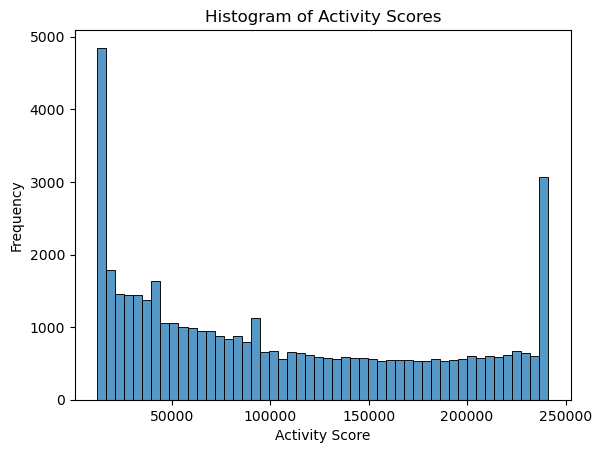

In [13]:
## Graphing Activity
sns.histplot(data=activities, x='Activity', bins=50, kde=False)
plt.xlabel('Activity Score')
plt.ylabel('Frequency')
plt.title('Histogram of Activity Scores')
plt.savefig(f'{dir}/Figs/{name}_ActivityScoreDist.jpg')
plt.show()

/global/software/rocky-8.x86_64/manual/modules/langs/anaconda3/2024.02-1/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


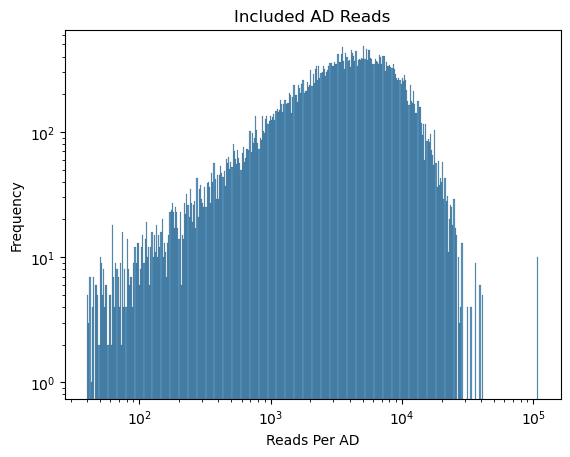

In [14]:
## Graphing AD reads

sns.histplot(data=total_reads_df, x='numreads_per_AD', bins=400, log_scale=(True, True))
plt.xlabel('Reads Per AD')
plt.ylabel('Frequency')
plt.title('Included AD Reads')
plt.savefig(f'{dir}/Figs/{name}_ADReadsDist.jpg')
plt.show()

/global/software/rocky-8.x86_64/manual/modules/langs/anaconda3/2024.02-1/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


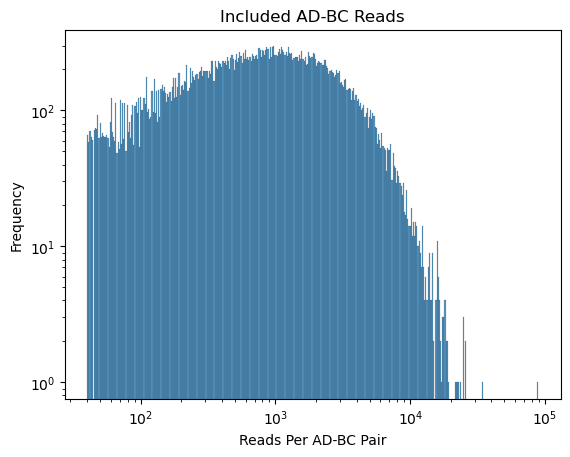

In [15]:
## Graphing AD-BC reads

sns.histplot(data=total_reads_df, x='Reads', bins=400, log_scale=(True, True))
plt.xlabel('Reads Per AD-BC Pair')
plt.ylabel('Frequency')
plt.title('Included AD-BC Reads')
plt.savefig(f'{dir}/Figs/{name}_ADBCReadsDist.jpg')
plt.show()